In [1]:
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.insert(0, '/content/drive/MyDrive/Stage')


Mounted at /content/drive


In [2]:
!pip install pytess


  Preparing metadata (setup.py) ... done
  Created wheel for pytess: filename=Pytess-1.0.0-py3-none-any.whl size=11830 sha256=722d4dc126da4aa5a4d862214ed76010f4c620e806b4fa73e0cbf02c94be327c
  Stored in directory: /root/.cache/pip/wheels/8f/e9/3f/fc9397ab46b758f8c1a4601e583a2221c88e8d3e3ac45bfefc
Successfully built pytess


In [3]:
import pandas as pd
import geopandas as gpd
import os
import numpy as np
from shapely import Polygon
from geo import build_geojson_point, get_clipped_voronoi_shapes

### Chargement des adresses du REU

In [4]:
df = pd.read_csv('/content/drive/MyDrive/Stage/table-adresses-reu.csv',
    dtype={
        'code_commune_ref': str,
         'reconstitution_code_commune': int,
         'id_brut_bv_reu': str,
         'id': str,
         'geo_adresse': str,
         'geo_type': str,
         'geo_score': float,
         'longitude': float,
         'latitude': float,
         'api_line': str,
         'nb_bv_commune': int,
         'nb_adresses': int
    }
)
df

,code_commune_ref,reconstitution_code_commune,id_brut_bv_reu,id,geo_adresse,geo_type,geo_score,longitude,latitude,api_line,nb_bv_commune,nb_adresses
0,01001,2,01001_1,01001_0045,Rue des Bles d'Or 01400 L'Abergement-Clémenciat,street,0.85,4.926090,46.151757,BANN,1,5
1,01001,1,01001_1,01001_0040_00101,101 Impasse Bellevue 01400 L'Abergement-Clémen...,housenumber,0.91,4.924261,46.134889,BANG,1,1
2,01001,1,01001_1,01001_0175_00106,106 Route des Garaudes 01400 L'Abergement-Clém...,housenumber,0.91,4.923428,46.133930,BANG,1,1
3,01001,1,01001_1,01001_0230_00190,190 Impasse des Lilas 01400 L'Abergement-Cléme...,housenumber,0.91,4.923083,46.146773,BANG,1,2
4,01001,2,01001_1,01001_0175_00192,192 Route des Garaudes 01400 L'Abergement-Clém...,housenumber,0.95,4.923743,46.133608,BANG,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...
15970987,97617,1,97617_99,97617_0277,ruelle du dojo 97680 Tsingoni,street,0.75,45.130008,-12.788336,BANG,9,1
15970988,97617,1,97617_99,97617_7l26gq,rue m'bourbo 97680 Tsingoni,street,0.40,45.137156,-12.786725,BANG,9,6
15970989,97617,1,97617_99,97617_0851,rue de la mosquée m'cafeni 97680 Tsingoni,street,0.51,45.103578,-12.789303,BAND,9,2
15970990,97617,1,97617_99,97617_1251,rue de la Rose 97680 Tsingoni,street,0.84,45.128281,-12.788653,BANG,9,3


### Création de la liste des départements

In [5]:
DEP_LIST = [
    "0"+str(i) for i in range(1, 10)
]+[
    str(i) for i in range(10, 20)
]+["2A", "2B"]+[
    str(i) for i in range(21, 96)
] + [
    str(i) for i in range(971, 977)
]

### Chargement des géométries des communes

In [6]:
commune_shapes_path = "http://etalab-datasets.geo.data.gouv.fr/contours-administratifs/2022/geojson/communes-5m.geojson"
communes_france = gpd.read_file(commune_shapes_path)
communes_france = communes_france.rename(
    {'code': 'insee'}, axis=1
)[['insee', 'geometry']]
communes_france

,insee,geometry
0,01001,"POLYGON ((4.95841 46.15327, 4.95812 46.15316, ..."
1,01002,"POLYGON ((5.4302 45.98278, 5.43001 45.98299, 5..."
2,01004,"POLYGON ((5.40882 45.94206, 5.4085 45.9421, 5...."
3,01005,"POLYGON ((4.94298 45.97962, 4.94257 45.97949, ..."
4,01006,"POLYGON ((5.57082 45.75338, 5.57219 45.75357, ..."
...,...,...
35089,98830,"MULTIPOLYGON (((165.25608 -20.86528, 165.25637..."
35090,98831,"MULTIPOLYGON (((164.69511 -21.04249, 164.69504..."
35091,98832,"MULTIPOLYGON (((167.03572 -22.29068, 167.03562..."
35092,98833,"MULTIPOLYGON (((165.88248 -21.39642, 165.88252..."


### Créations de contours des bureaux de vote par département

In [ ]:
import os

base_path = "/content/drive/MyDrive/Stage"

geojson_path = os.path.join(base_path, "geojson")

if not os.path.exists(geojson_path):
    os.mkdir(geojson_path)
    print("Dossier créé :", geojson_path)
else:
    print("Le dossier existe déjà :", geojson_path)

for DEP in DEP_LIST:
    print(DEP)
    addresses_df = df.loc[df['code_commune_ref'].str.startswith(DEP)].copy()

    communes_dep = communes_france[communes_france.insee.str.startswith(str(DEP))]
    codes2drop = ('13055', '75056', '69123')
    communes_dep = communes_dep.loc[~(communes_dep['insee'].str.startswith(codes2drop))]


    addresses_df['id_bv'] = addresses_df['id_brut_bv_reu']
    addresses_df['commune_bv'] = addresses_df['code_commune_ref']

    geo_addresses = build_geojson_point(addresses_df)
    hulls = get_clipped_voronoi_shapes(geo_addresses, communes_dep)
    id_bvs = []
    coordinates = []

    for _, row in hulls.iterrows():
        id_bvs.append(row["id_bv"])
        try:
            coord = Polygon(
                [
                    list(x)
                    for x in np.transpose(
                        [
                            list(row["geometry"].exterior.coords.xy[0]),
                            list(row["geometry"].exterior.coords.xy[1]),
                        ]
                    )
                ]
            )
            coordinates.append(coord)
        except Exception as e:
            coordinates.append([])
            pass

    voronoi_polygons = gpd.GeoDataFrame(
        pd.DataFrame(data={"coordinates": coordinates, "id_bv": id_bvs}),
        geometry='coordinates'
    )

    for main_idx in voronoi_polygons.index:
        for side_idx in voronoi_polygons.index:
            if main_idx != side_idx:
                if voronoi_polygons.loc[main_idx, 'coordinates'].contains(voronoi_polygons.loc[side_idx, 'coordinates']):
                    voronoi_polygons.loc[main_idx, 'coordinates'] = voronoi_polygons.loc[main_idx, 'coordinates'].difference(voronoi_polygons.loc[side_idx, 'coordinates'])

    voronoi_polygons = voronoi_polygons.dissolve('id_bv').reset_index(names='id_bv').reset_index(names='id')


    output_path = os.path.join(geojson_path, f"voronoi_contours_{DEP}.geojson")

    voronoi_polygons['id'] = voronoi_polygons['id'].astype(int)

    with open(output_path, 'w') as f:
        f.write(voronoi_polygons.to_json())

    print(f"  DEP {DEP} : {len(addresses_df):>8} adresses | {len(voronoi_polygons):>4} bureaux de vote ")
    print("-" * 55)



Dossier créé : /content/drive/MyDrive/Stage/geojson
01
  DEP 01 :   169464 adresses |  583 bureaux de vote 
-------------------------------------------------------
02
  DEP 02 :   167320 adresses |  973 bureaux de vote 
-------------------------------------------------------
03
  DEP 03 :   108619 adresses |  451 bureaux de vote 
-------------------------------------------------------
04
  DEP 04 :    40847 adresses |  262 bureaux de vote 
-------------------------------------------------------
05
  DEP 05 :    30479 adresses |  205 bureaux de vote 
-------------------------------------------------------
06
  DEP 06 :   119162 adresses |  980 bureaux de vote 
-------------------------------------------------------
07
  DEP 07 :   105782 adresses |  440 bureaux de vote 
-------------------------------------------------------
08
  DEP 08 :    84556 adresses |  559 bureaux de vote 
-------------------------------------------------------
09
  DEP 09 :    46159 adresses |  379 bureaux de vo

### Visualisation du découpage pour chaque département

DEP 69 chargé : 1316 polygones
DEP 75 chargé : 897 polygones
DEP 48 chargé : 188 polygones


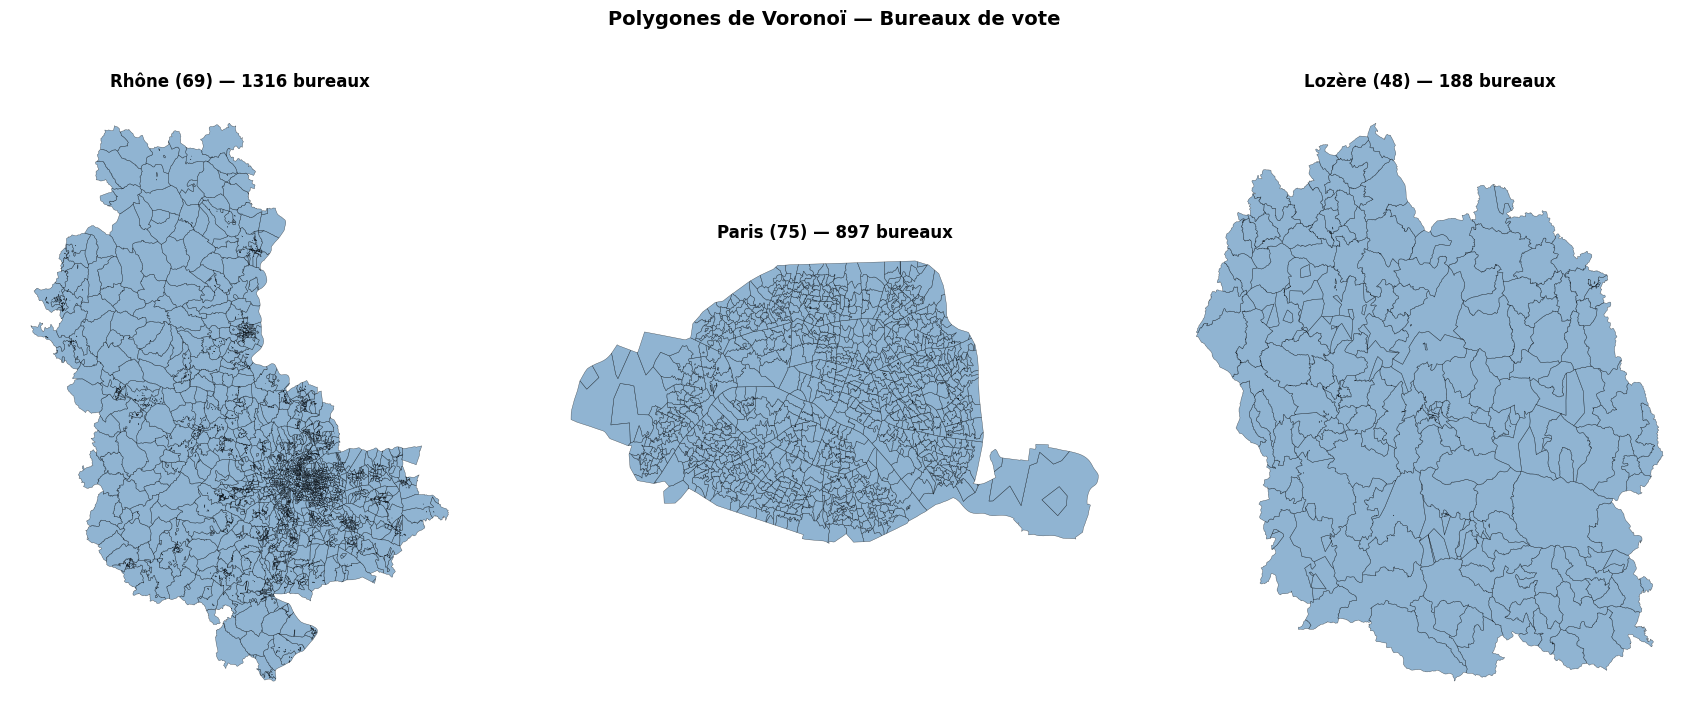

In [ ]:
import matplotlib.pyplot as plt
import geopandas as gpd

deps_info = [
    ("69", "Rhône (69) — 1316 bureaux"),
    ("75", "Paris (75) — 897 bureaux"),
    ("48", "Lozère (48) — 188 bureaux"),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, (DEP, titre) in zip(axes, deps_info):
    try:
        contours = gpd.read_file(f'/content/drive/MyDrive/Stage/geojson/voronoi_contours_{DEP}.geojson')
        contours.plot(
            ax=ax,
            edgecolor='black',
            linewidth=0.3,
            facecolor='steelblue',
            alpha=0.6
        )
        ax.set_title(titre, fontsize=12, fontweight='bold')
        ax.axis('off')
        print(f"DEP {DEP} chargé : {len(contours)} polygones")
    except Exception as e:
        print(f"Erreur DEP {DEP} : {e}")
        ax.set_title(f"DEP {DEP} — ERREUR", fontsize=12)
        ax.axis('off')

plt.suptitle("Polygones de Voronoï — Bureaux de vote", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Création du fichier geojson à l'échelle de la France

In [7]:
import os
import geopandas as gpd
import pandas as pd

BASE = "/content/drive/MyDrive/Stage/geojson"
contours_france = []
for DEP in DEP_LIST:
    try:
        file_path = os.path.join(BASE, f"voronoi_contours_{DEP}.geojson")
        contours = gpd.read_file(file_path)
        contours_france.append(contours)
    except Exception as e:
        print("Erreur pour DEP", DEP)
        print(e)

# Concaténation
contours_france = pd.concat(contours_france, ignore_index=True)

# Conversion en GeoDataFrame
geo_contours_france = gpd.GeoDataFrame(contours_france)

# Suppression de la colonne id
if "id" in geo_contours_france.columns:
    geo_contours_france = geo_contours_france.drop(columns=["id"])
geo_contours_france

,id_bv,geometry
0,01001_1,"POLYGON ((4.95812 46.15316, 4.95771 46.15288, ..."
1,01002_1,"POLYGON ((5.43001 45.98299, 5.4298 45.98312, 5..."
2,01004_1,"POLYGON ((5.33312 45.95904, 5.33358 45.95987, ..."
3,01004_2,"MULTIPOLYGON (((5.35287 45.95468, 5.35225 45.9..."
4,01004_3,"POLYGON ((5.36082 45.94544, 5.36069 45.94558, ..."
...,...,...
68801,97617_23,"MULTIPOLYGON (((45.1332 -12.79175, 45.13341 -1..."
68802,97617_49,"MULTIPOLYGON (((45.13359 -12.79192, 45.13344 -..."
68803,97617_73,"MULTIPOLYGON (((45.09781 -12.79254, 45.09773 -..."
68804,97617_74,"MULTIPOLYGON (((45.13136 -12.79085, 45.13146 -..."


### Visualisation du découpage en métropole (pour plus de lisibilité)

<Axes: >

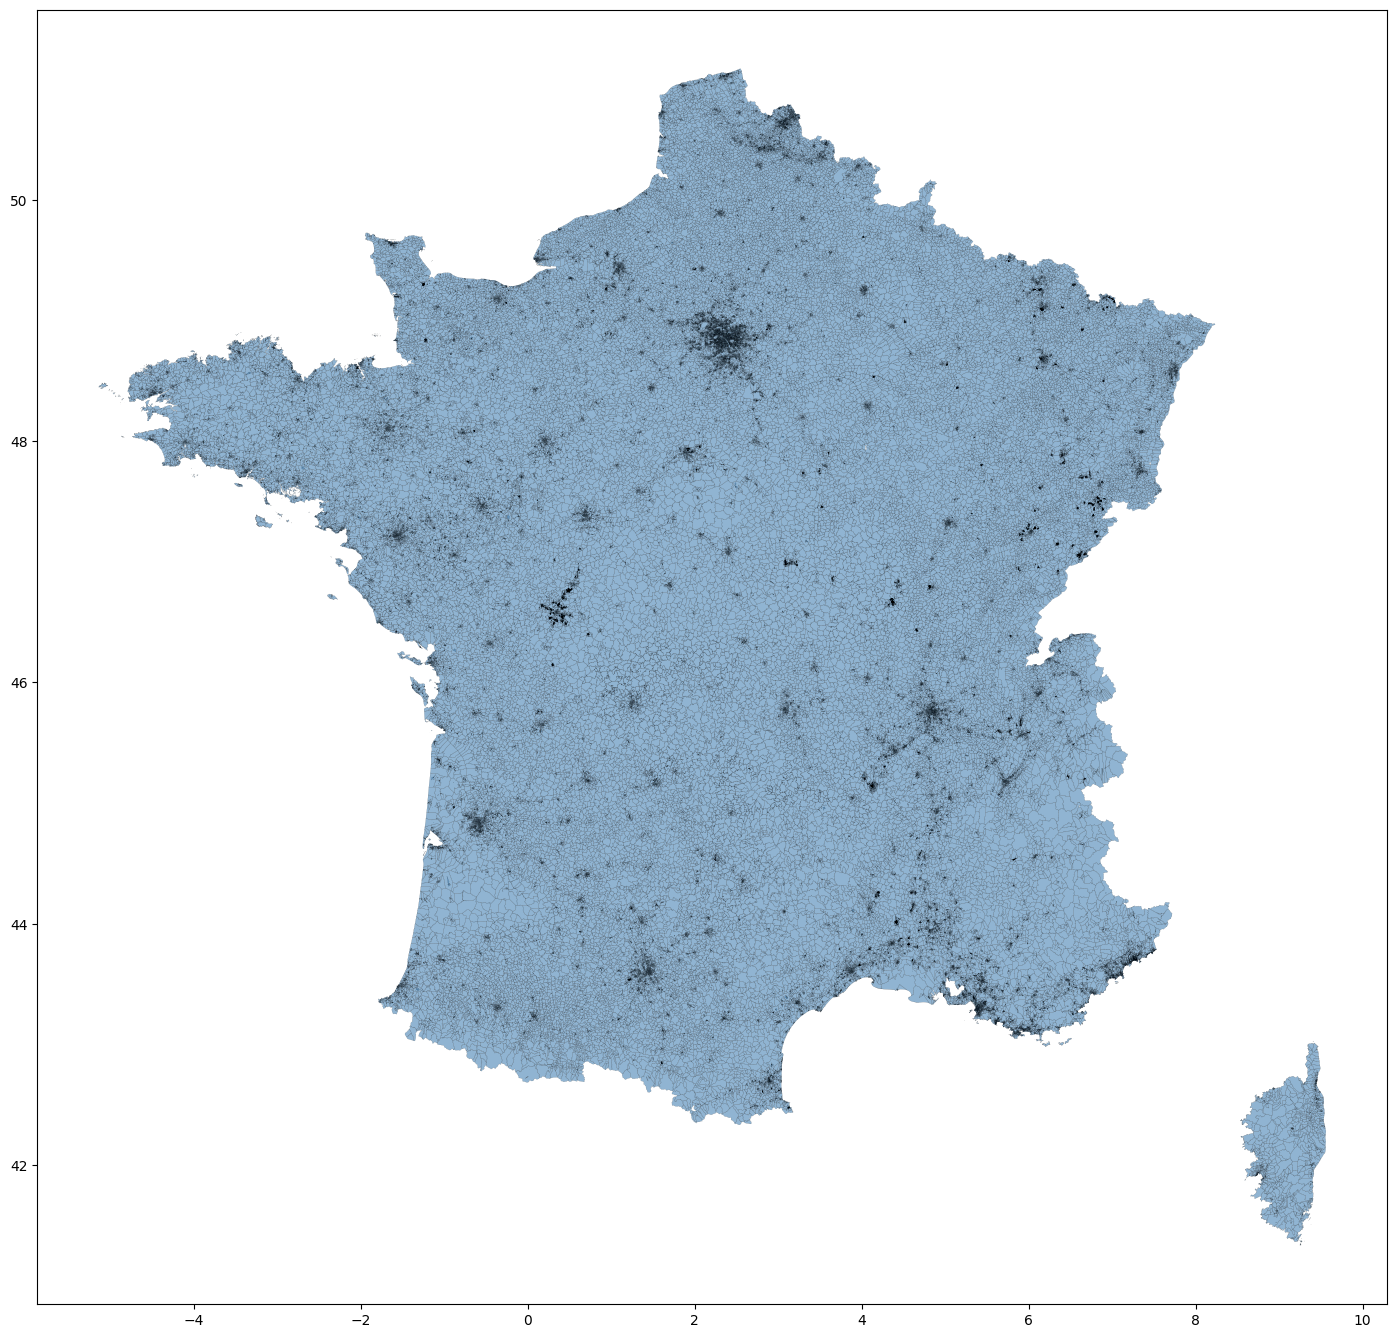

In [ ]:
import matplotlib.pyplot as plt
metropole = geo_contours_france[
    ~geo_contours_france['id_bv'].str.startswith('97')
]
# Création de la figure principale
fig = plt.figure(figsize=(18, 22))

# Axe principal pour la métropole
ax_main = fig.add_axes([0.05, 0.05, 0.75, 0.9])
metropole.plot(ax=ax_main, facecolor='steelblue', linewidth=0.1, edgecolor='black', alpha=0.6)


# Carte France entière + DOM‑TOM en encadrés

In [ ]:
import matplotlib.pyplot as plt
import geopandas as gpd

metropole = geo_contours_france[~geo_contours_france['id_bv'].str.startswith('97')]
domtom = geo_contours_france[geo_contours_france['id_bv'].str.startswith('97')]

DOM_LIST = {
    "971": "Guadeloupe",
    "972": "Martinique",
    "973": "Guyane",
    "974": "Réunion",
    "975": "St-Pierre",
    "976": "Mayotte"
}

fig = plt.figure(figsize=(20, 24))

# Métropole
ax_main = fig.add_axes([0.02, 0.02, 0.74, 0.96])
metropole.plot(ax=ax_main, facecolor='steelblue', linewidth=0.1,
               edgecolor='black', alpha=0.6)
ax_main.set_title("France métropolitaine\nVoronoï des bureaux de vote",
                  fontsize=13, fontweight='bold')
ax_main.axis("off")

# DOM-TOM — 6 vignettes réparties sur la hauteur
n = len(DOM_LIST)
h = 0.90 / n  # hauteur de chaque vignette
y_start = 0.97

for i, (dep, name) in enumerate(DOM_LIST.items()):
    y = y_start - (i + 1) * h
    ax = fig.add_axes([0.78, y + 0.01, 0.20, h - 0.02])
    subset = domtom[domtom['id_bv'].str.startswith(dep)]
    if len(subset) > 0:
        subset.plot(ax=ax, facecolor='steelblue', linewidth=0.2,
                    edgecolor='black', alpha=0.6)
        ax.set_title(f"{name} ({len(subset)} bv)", fontsize=9)
    else:
        ax.set_title(f"{name} — données manquantes", fontsize=9, color='red')
    ax.axis("off")

plt.suptitle("Polygones de Voronoï — Bureaux de vote France entière",
             fontsize=15, fontweight='bold', y=1.001)
plt.show()

Output hidden; open in https://colab.research.google.com to view.

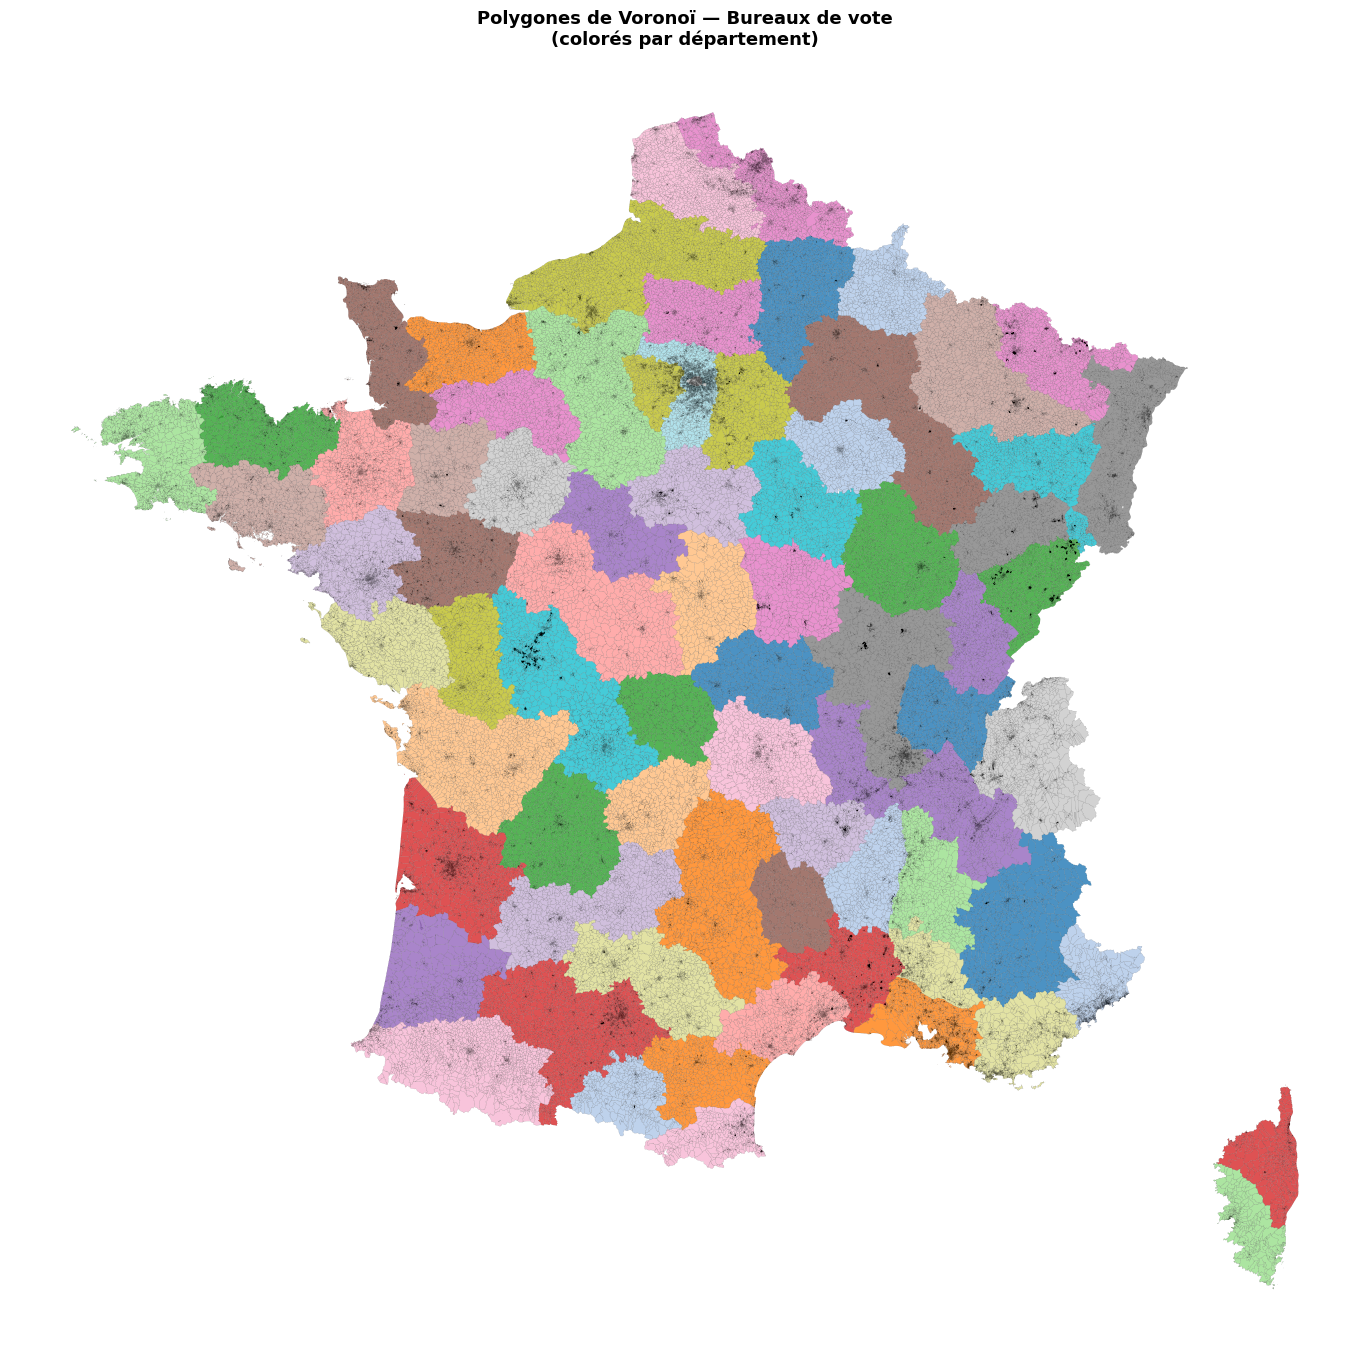

In [11]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

metropole = geo_contours_france[
    ~geo_contours_france['id_bv'].str.startswith('97')
].copy()

# Extraire le code département depuis id_bv (2 premiers caractères)
metropole['dep'] = metropole['id_bv'].str[:2]

# Créer un code numérique pour la couleur
deps_uniques = metropole['dep'].unique()
dep_to_num = {dep: i for i, dep in enumerate(sorted(deps_uniques))}
metropole['dep_num'] = metropole['dep'].map(dep_to_num)

fig = plt.figure(figsize=(18, 22))
ax_main = fig.add_axes([0.05, 0.05, 0.75, 0.9])

metropole.plot(
    ax=ax_main,
    column='dep_num',
    cmap='tab20',
    linewidth=0.05,
    edgecolor='black',
    alpha=0.8,
    legend=False
)
ax_main.set_title("Polygones de Voronoï — Bureaux de vote\n(colorés par département)",
                  fontsize=13, fontweight='bold')
ax_main.axis('off')
plt.show()

# Carte interactive Folium

In [ ]:
import folium
from folium.features import GeoJsonTooltip

# ← Un seul département pour la carte interactive
DEP = "69"
contours_dep = geo_contours_france[
    geo_contours_france['id_bv'].str.startswith(DEP)
].copy()

centroid = contours_dep.geometry.unary_union.centroid
m = folium.Map(location=[centroid.y, centroid.x],
               zoom_start=11, tiles="cartodbpositron")

folium.GeoJson(
    contours_dep,
    name=f"Voronoï DEP {DEP}",
    style_function=lambda x: {
        "fillColor": "#3186cc",
        "color": "black",
        "weight": 0.5,
        "fillOpacity": 0.4
    },
    tooltip=GeoJsonTooltip(
        fields=["id_bv"],
        aliases=["Bureau de vote :"],
        sticky=True
    )
).add_to(m)

folium.LayerControl().add_to(m)
m

Output hidden; open in https://colab.research.google.com to view.

### Export en geojson

In [ ]:
OUTPUT_DIR = "/content/drive/MyDrive/Stage/geojson"

geo_contours_france.to_file(
    f"{OUTPUT_DIR}/contours_france_entiere.geojson",
    driver="GeoJSON"
)


In [ ]:
print("Exemples id_bv Voronoï :")
print(geo_contours_france['id_bv'].sample(10).tolist())

Exemples id_bv Voronoï :
['50285_1', '89230_1', '22348_1', '56166_4', '74225_1', '44198_1', '13028_9', '45142_2', '53104_2', '54338_1']
